In [1]:
import pandas as pd
import torch
import numpy as np
import random

In [2]:
train_data = pd.read_csv("../data/logistic_growth_train.csv")
test_data = pd.read_csv("../data/logistic_growth_test.csv")

In [3]:
train_data.head()

,L0_initial,growth_rate_a,competition_coeff_b,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,...,L_t90,L_t91,L_t92,L_t93,L_t94,L_t95,L_t96,L_t97,L_t98,L_t99
0,33.090710,0.371776,0.009158,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,40.593517,40.587255,40.581092,40.575867,40.572564,40.572313,40.575604,40.578874,40.581583,40.583828
1,47.129551,0.453238,0.001284,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,352.809044,352.843019,352.868486,352.884291,352.890521,352.888510,352.880828,352.871294,352.864964,352.868141
2,19.639865,0.197991,0.001407,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,140.603070,140.609302,140.615048,140.620868,140.627370,140.635091,140.642624,140.649441,140.655610,140.661192
3,30.488209,0.459523,0.003674,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,125.033383,125.044394,125.053031,125.058881,125.061897,125.062401,125.061080,125.058988,125.057546,125.058541
4,47.760681,0.558657,0.002231,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,250.454216,250.461245,250.448120,250.416163,250.369764,250.316377,250.266520,250.233778,250.234799,250.265873


# Prosty Model

In [5]:
import torch
from torch.utils.data import DataLoader, Dataset
from sklearn.preprocessing import StandardScaler

def prepare_data(df):

    params = df.iloc[:, :4].values 
    
    t_grid = df.filter(like='t_grid').values
    
    # 3. Wyniki (Targets) - L_t0 do L_t99
    y_values = df.filter(like='L_t').values
    
    return params, t_grid, y_values

# Przetwarzanie
params_train, t_train, y_train = prepare_data(train_data)
params_test, t_test, y_test = prepare_data(test_data)

scaler_params = StandardScaler()
params_train = scaler_params.fit_transform(params_train)
params_test = scaler_params.transform(params_test)

In [19]:
class DeepONetDataset(Dataset):
    def __init__(self, branch_inputs, trunk_inputs, targets):
        self.branch_inputs = torch.FloatTensor(branch_inputs)
        self.trunk_inputs = torch.FloatTensor(trunk_inputs)
        self.targets = torch.FloatTensor(targets)

    def __len__(self):
        return len(self.branch_inputs)

    def __getitem__(self, idx):
        # Branch: [1, 4] dla CNN1D
        branch = self.branch_inputs[idx].unsqueeze(0)
        # Trunk: [100]
        trunk = self.trunk_inputs[idx]
        # Target: [100]
        y = self.targets[idx]
        return branch, trunk, y

# Inicjalizacja DataLoaderów
train_dataset = DeepONetDataset(params_train, t_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

test_dataset = DeepONetDataset(params_test, t_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [20]:
# 1. Definicja Architektury ConvDeepONet
class ConvDeepONet(nn.Module):
    def __init__(self, p=64):
        super(ConvDeepONet, self).__init__()

        # Wejście: [Batch, 1, 4] -> Wyjście: [Batch, p]
        self.branch = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=2), 
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=2),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 2, p) 
        )
        
        # Wejście: [Batch * 100, 1] -> Wyjście: [Batch * 100, p]
        self.trunk = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, p),
            nn.ReLU()
        )
        
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, x_branch, x_trunk):
        
        B = self.branch(x_branch) 
        
        batch_size, num_points = x_trunk.shape
        t_flat = x_trunk.view(-1, 1) 
        T_flat = self.trunk(t_flat)  
        
        T = T_flat.view(batch_size, num_points, -1) # [Batch, 100, p]
        B = B.unsqueeze(1)                           # [Batch, 1, p]
        
        out = torch.sum(B * T, dim=-1) + self.bias
        return out

In [21]:
operator = ConvDeepONet(p=128) 
optimizer = optim.Adam(operator.parameters(), lr=1e-3)
criterion = nn.MSELoss()

train_losses = []
val_losses = []

epochs = 20

for epoch in range(epochs):
    operator.train()
    total_loss = 0
    
    for batch_branch, batch_trunk, batch_y in train_loader:
        optimizer.zero_grad()
        
        output = operator(batch_branch, batch_trunk)
        
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_train_loss = total_loss / len(train_loader)
    train_losses.append(avg_train_loss) 
    
    # Walidacja
    operator.eval()
    total_val_loss = 0
    with torch.no_grad():
        for v_branch, v_trunk, v_y in test_loader:
            val_output = operator(v_branch, v_trunk)
            v_loss = criterion(val_output, v_y)
            total_val_loss += v_loss.item()
            
    avg_val_loss = total_val_loss / len(test_loader)
    val_losses.append(avg_val_loss)
        
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")

Epoch [1/20] | Train Loss: 10816.332689 | Val Loss: 6581.247192
Epoch [2/20] | Train Loss: 5472.118333 | Val Loss: 4066.320068
Epoch [3/20] | Train Loss: 3545.758705 | Val Loss: 3222.822144
Epoch [4/20] | Train Loss: 2956.396625 | Val Loss: 2784.435852
Epoch [5/20] | Train Loss: 2465.179378 | Val Loss: 2520.021942
Epoch [6/20] | Train Loss: 2266.949322 | Val Loss: 2267.153748
Epoch [7/20] | Train Loss: 1955.547138 | Val Loss: 1987.581879
Epoch [8/20] | Train Loss: 1698.299777 | Val Loss: 1868.589874
Epoch [9/20] | Train Loss: 1611.168128 | Val Loss: 1712.837708
Epoch [10/20] | Train Loss: 1556.465055 | Val Loss: 1665.569275
Epoch [11/20] | Train Loss: 1275.132348 | Val Loss: 1141.599365
Epoch [12/20] | Train Loss: 985.264120 | Val Loss: 1235.437073
Epoch [13/20] | Train Loss: 992.202956 | Val Loss: 891.485039
Epoch [14/20] | Train Loss: 678.365481 | Val Loss: 739.590546
Epoch [15/20] | Train Loss: 609.119995 | Val Loss: 677.276627
Epoch [16/20] | Train Loss: 538.034978 | Val Loss: 683.

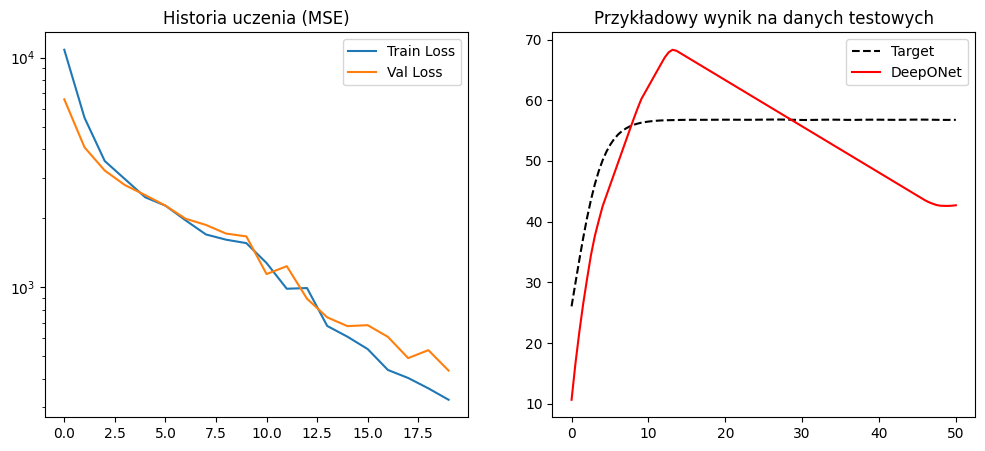

In [23]:
plt.figure(figsize=(12, 5))

# Wykres błędu
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.yscale('log')
plt.title('Historia uczenia (MSE)')
plt.legend()

# Przykładowa predykcja
plt.subplot(1, 2, 2)
with torch.no_grad():
    sample_b, sample_t, sample_y = next(iter(test_loader))
    pred = operator(sample_b, sample_t)[0]
    plt.plot(sample_t[0], sample_y[0], 'k--', label='Target')
    plt.plot(sample_t[0], pred, 'r', label='DeepONet')
    plt.title('Przykładowy wynik na danych testowych')
    plt.legend()

plt.show()

# Random Search

In [25]:
class ConvDeepONet(nn.Module):
    def __init__(self, p=128, hidden_dim=64):
        super(ConvDeepONet, self).__init__()
        
        self.branch = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=2), 
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=2),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 2, p) 
        )
        
        self.trunk = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, p),
            nn.ReLU()
        )
        
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, x_branch, x_trunk):
        B = self.branch(x_branch) 
        
        batch_size, num_points = x_trunk.shape
        t_flat = x_trunk.view(-1, 1) 
        T_flat = self.trunk(t_flat)  
        
        T = T_flat.view(batch_size, num_points, -1)
        B = B.unsqueeze(1) 
        
        out = torch.sum(B * T, dim=-1) + self.bias
        return out

In [26]:
def train_deeponet(config, train_loader, test_loader, epochs):
    model = ConvDeepONet(p=config['p'], hidden_dim=config['hidden_dim'])
    
    if config['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    else:
        optimizer = optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
        
    criterion = nn.MSELoss()
    history = {'train': [], 'val': []}
    
    for epoch in range(epochs):
        model.train()
        t_loss = 0
        for b, t, y in train_loader:
            optimizer.zero_grad()
            out = model(b, t)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            t_loss += loss.item()
            
        model.eval()
        v_loss = 0
        with torch.no_grad():
            for b, t, y in test_loader:
                v_loss += criterion(model(b, t), y).item()
                
        history['train'].append(t_loss / len(train_loader))
        history['val'].append(v_loss / len(test_loader))
        
    return model, history

In [37]:
import random

param_grid = {
    'p': [64, 128, 256, 512],                  # Rozmiar przestrzeni bazowej (końcówka Branch i Trunk)
    'hidden_dim': [32, 64, 128, 256],          # Szerokość warstw ukrytych w Trunk Net
    'lr': [1e-3, 5e-4, 1e-4, 5e-5],            # Współczynnik uczenia
    'weight_decay': [0.0, 1e-5, 1e-4],         # Regularyzacja L2
    'optimizer': ['Adam', 'AdamW']             # Rodzaj optymalizatora
}

best_val_loss = float('inf')
best_config = None


num_search_trials = 8
print("--- ROZPOCZYNAM RANDOM SEARCH ---")

for i in range(num_search_trials):
    config = {k: random.choice(v) for k, v in param_grid.items()}
    print(f"Próba {i+1}/{num_search_trials} | Konfiguracja: {config}")
    
    # Trenujemy krótko (15 epok), żeby tylko ocenić potencjał konfiguracji
    _, history = train_deeponet(config, train_loader, test_loader, epochs=15)
    final_val = history['val'][-1]
    print(f"-> Wynik po 15 epokach (Val Loss): {final_val:.6f}")
    
    if final_val < best_val_loss:
        best_val_loss = final_val
        best_config = config

print(f"\n[SUKCES] Wybrano najlepszą konfigurację: {best_config}")



--- ROZPOCZYNAM RANDOM SEARCH ---
Próba 1/8 | Konfiguracja: {'p': 256, 'hidden_dim': 256, 'lr': 0.001, 'weight_decay': 1e-05, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 599.160374
Próba 2/8 | Konfiguracja: {'p': 64, 'hidden_dim': 32, 'lr': 0.0005, 'weight_decay': 0.0, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 2453.163116
Próba 3/8 | Konfiguracja: {'p': 512, 'hidden_dim': 32, 'lr': 5e-05, 'weight_decay': 0.0, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 5975.302368
Próba 4/8 | Konfiguracja: {'p': 256, 'hidden_dim': 256, 'lr': 5e-05, 'weight_decay': 1e-05, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 3026.053467
Próba 5/8 | Konfiguracja: {'p': 128, 'hidden_dim': 64, 'lr': 0.0001, 'weight_decay': 0.0, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 5222.174500
Próba 6/8 | Konfiguracja: {'p': 256, 'hidden_dim': 256, 'lr': 5e-05, 'weight_decay': 1e-05, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 3388.387085
Próba 7/8 | K

In [38]:

print(f"Trening od nowa na najlepszym zestawie {best_config}")

FINAL_EPOCHS = 100  


operator = ConvDeepONet(p=best_config['p'], hidden_dim=best_config['hidden_dim'])


if best_config['optimizer'] == 'Adam':
    optimizer = optim.Adam(operator.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])
else:
    optimizer = optim.AdamW(operator.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])

criterion = torch.nn.MSELoss()




best_val_loss = float('inf')
final_history = {'train': [], 'val': []}

for epoch in range(FINAL_EPOCHS):
    operator.train()
    total_train_loss = 0
    for b_branch, b_trunk, b_y in train_loader:
        optimizer.zero_grad()
        output = operator(b_branch, b_trunk)
        loss = criterion(output, b_y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
        
    # Ewaluacja
    operator.eval()
    total_val_loss = 0
    with torch.no_grad():
        for v_branch, v_trunk, v_y in test_loader:
            v_output = operator(v_branch, v_trunk)
            v_loss = criterion(v_output, v_y)
            total_val_loss += v_loss.item()
            
    avg_train = total_train_loss / len(train_loader)
    avg_val = total_val_loss / len(test_loader)
    
    final_history['train'].append(avg_train)
    final_history['val'].append(avg_val)
    
    # Zapisz model, jeśli jest najlepszy do tej pory (dokładnie jak w Twoim przykładzie)
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(operator.state_dict(), 'best_deeponet_model.pth')
        status = " [MODEL SAVED]"
    else:
        status = ""
        
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] | Train: {avg_train:.6f} | Val: {avg_val:.6f}{status}")

print(f"\nTrening zakończony. Najlepszy Val Loss: {best_val_loss:.6f}")

Trening od nowa na najlepszym zestawie {'p': 256, 'hidden_dim': 256, 'lr': 0.001, 'weight_decay': 1e-05, 'optimizer': 'Adam'}
Epoch [1/100] | Train: 8045.288311 | Val: 5608.854553 [MODEL SAVED]
Epoch [10/100] | Train: 631.171694 | Val: 1022.764252
Epoch [20/100] | Train: 135.956262 | Val: 241.257156 [MODEL SAVED]
Epoch [30/100] | Train: 115.643298 | Val: 161.342489 [MODEL SAVED]
Epoch [40/100] | Train: 64.318039 | Val: 123.489063
Epoch [50/100] | Train: 43.522208 | Val: 108.403408 [MODEL SAVED]
Epoch [60/100] | Train: 43.807901 | Val: 69.945749 [MODEL SAVED]
Epoch [70/100] | Train: 41.930961 | Val: 81.073264
Epoch [80/100] | Train: 46.495324 | Val: 82.931347
Epoch [90/100] | Train: 23.167456 | Val: 140.614597
Epoch [100/100] | Train: 68.726535 | Val: 85.020875

Trening zakończony. Najlepszy Val Loss: 51.418040


In [39]:
def plot_mean_and_variance(model, loader, filename="logistic_stats_deeponet.png"):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for b_branch, b_trunk, b_y in loader:
            preds = model(b_branch, b_trunk)
            all_preds.append(preds)
            all_targets.append(b_y)
    
    all_preds = torch.cat(all_preds, dim=0).squeeze()
    all_targets = torch.cat(all_targets, dim=0).squeeze()
    
    mean_pred = all_preds.mean(dim=0).numpy()
    std_pred = all_preds.std(dim=0).numpy()
    mean_target = all_targets.mean(dim=0).numpy()
    std_target = all_targets.std(dim=0).numpy()
    
    t_axis = range(len(mean_pred))
    
    plt.figure(figsize=(12, 6))
    plt.plot(t_axis, mean_target, color='black', label='Średnia Solver ODE', lw=2)
    plt.fill_between(t_axis, mean_target - std_target, mean_target + std_target, 
                     color='black', alpha=0.1, label='Wariancja populacji (Solver)')
    
    plt.plot(t_axis, mean_pred, color='red', linestyle='--', label='Średnia DeepONet', lw=2)
    plt.fill_between(t_axis, mean_pred - std_pred, mean_pred + std_pred, 
                     color='red', alpha=0.2, label='Wariancja predykcji (DeepONet)')
    
    plt.title('Statystyka zbiorcza: Dynamika wzrostu populacji $L(t)$')
    plt.xlabel('Czas ($t$)')
    plt.ylabel('Populacja ($L$)')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Plik {filename} został zapisany pomyślnie.")
    plt.show()

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def plot_history(history, filename="loss_history_deeponet.png"):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train'], label='Błąd Treningowy', color='#1f77b4')
    plt.plot(history['val'], label='Błąd Walidacyjny', color='#ff7f0e')
    plt.yscale('log')
    plt.title('Krzywa uczenia DeepONet ($dL/dt = aL - bL^2$)')
    plt.xlabel('Epoka')
    plt.ylabel('MSE Loss (Log Scale)')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

def visualize_results(model, loader, num_samples=3, filename="logistic_samples_deeponet.png"):
    model.eval()

    b_in, t_in, y_true = next(iter(loader))
    b_in, t_in, y_true = b_in[:num_samples], t_in[:num_samples], y_true[:num_samples]
    
    with torch.no_grad():
 
        preds = model(b_in, t_in)
    
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))
    
    for i in range(num_samples):
        axes[i, 0].plot(y_true[i].numpy().flatten(), label='Solver ODE (Target)', color='black', lw=2)
        axes[i, 0].plot(preds[i].numpy().flatten(), label='DeepONet (Prediction)', color='red', linestyle='--')
        axes[i, 0].set_title(f'Przykładowa ewolucja populacji L(t) - Próba {i+1}')
        axes[i, 0].set_xlabel('Kroki czasowe')
        axes[i, 0].set_ylabel('Populacja $L$')
        axes[i, 0].legend()
        
        # Błąd bezwzględny w czasie
        error = torch.abs(y_true[i] - preds[i]).numpy().flatten()
        axes[i, 1].fill_between(range(len(error)), error, color='red', alpha=0.3)
        axes[i, 1].set_title(f'Błąd bezwzględny $|L_{{true}} - L_{{pred}}|$')
        axes[i, 1].set_xlabel('Kroki czasowe')
        
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

Zapisano: loss_history_deeponet.png


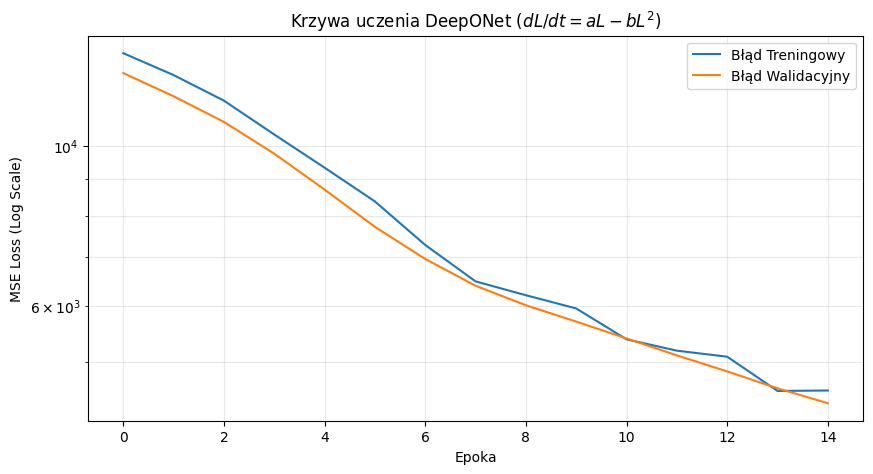

Zapisano: logistic_samples_deeponet.png


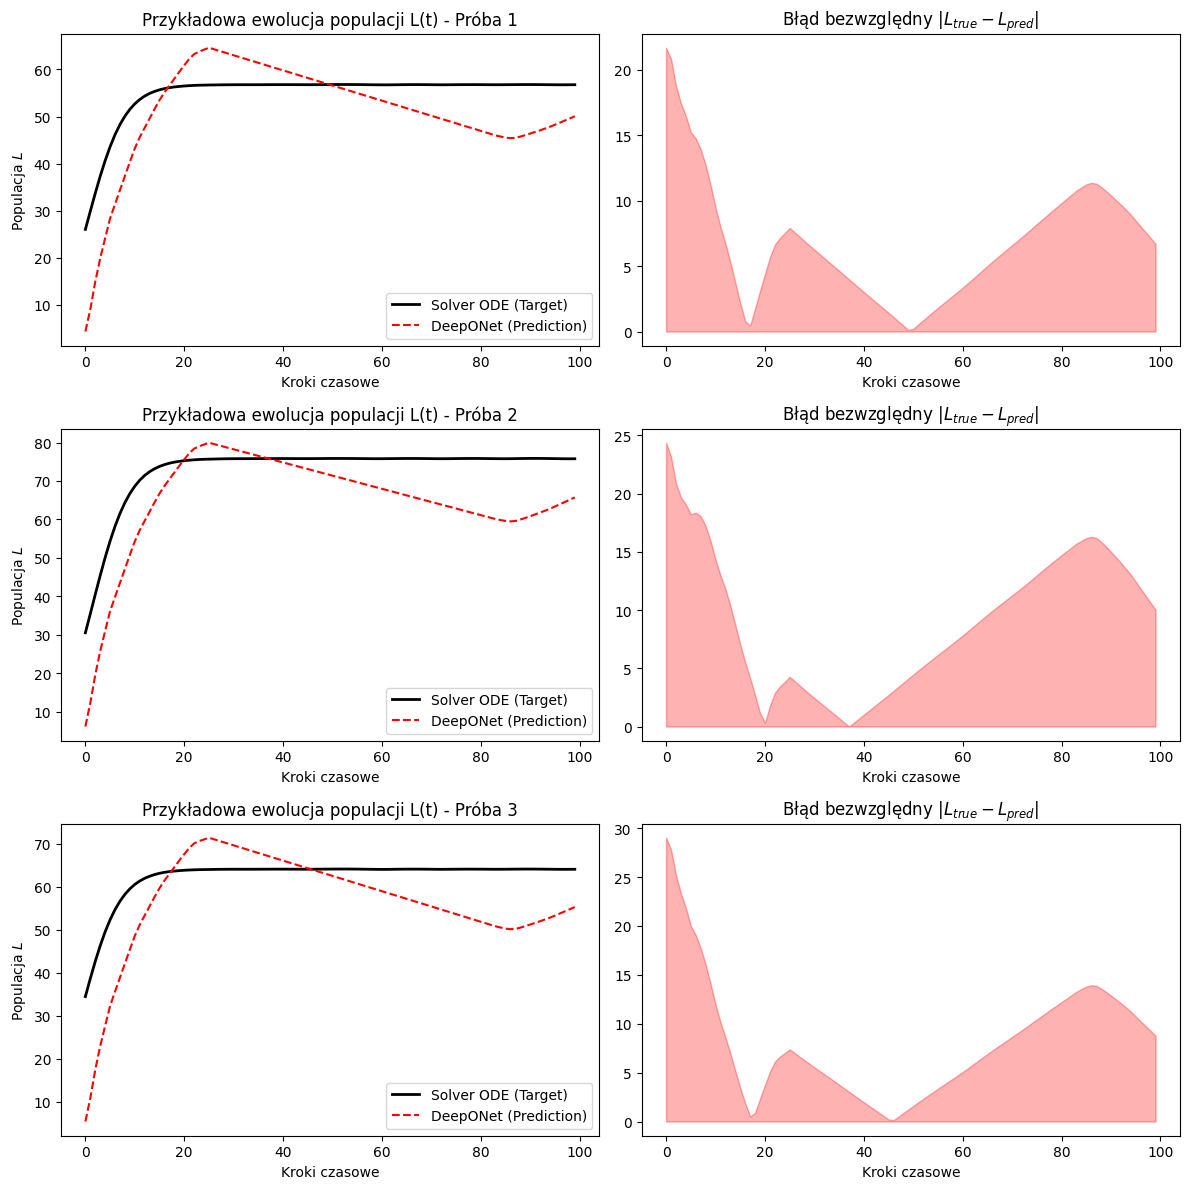

Plik logistic_stats_deeponet.png został zapisany pomyślnie.


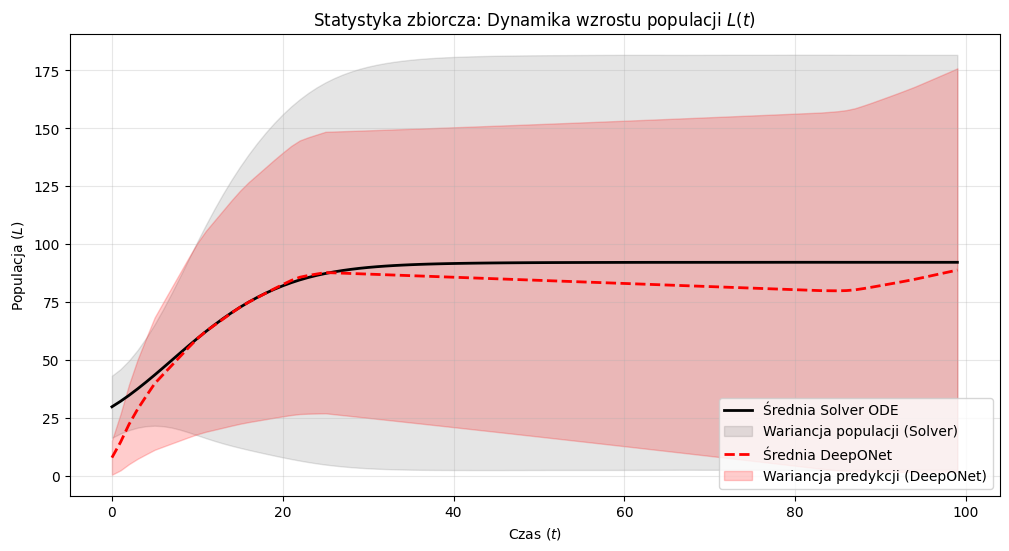

In [41]:
plot_history(history)
visualize_results(model, test_loader)
plot_mean_and_variance(model, test_loader)